In [4]:
from pathlib import Path
import random
import subprocess as sbp
import pandas as pd
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import seaborn as sns
from tqdm.auto import tqdm
from joblib import Parallel, delayed

SAMPLES = 1e7

random.seed(231)

popes = pd.read_csv("../popes-list.csv")

### Figure 1

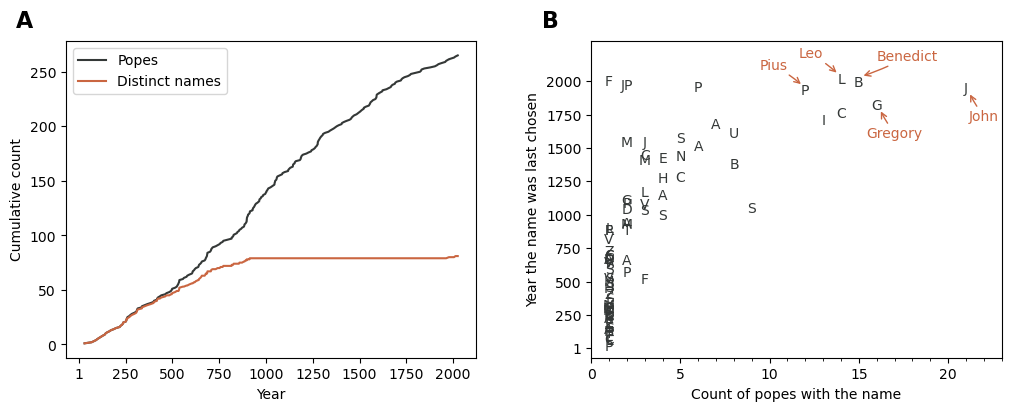

In [2]:
rows = []
for i in range(1, popes.shape[0] + 1):
    di = popes.iloc[:i, :]

    rows.append(
        {"year": di["start"].iloc[-1], "n": i, "names": len(di["name"].unique())}
    )

dc = pd.DataFrame.from_records(rows).sort_values(by="year")


rows = []
for name in popes["name"].unique():
    dn = popes.query("name == @name")

    rows.append(
        {
            "name": dn["pope"].iloc[0],
            "count": dn.shape[0],
            "last_seen": dn["start"].max(),
        }
    )

dn = pd.DataFrame.from_records(rows)

fig, axs = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True, gridspec_kw={"wspace": 0.1}
)
colors = sns.xkcd_palette(["charcoal", "terracotta"])

ax = axs[0]
sns.lineplot(dc, x="year", y="n", label="Popes", color=colors[0], ax=ax)
sns.lineplot(dc, x="year", y="names", label="Distinct names", color=colors[1], ax=ax)

ax.set_xlabel("Year")
ax.set_ylabel("Cumulative count")
ax.set_xticks([1, 250, 500, 750, 1000, 1250, 1500, 1750, 2000])

ax = axs[1]
sns.scatterplot(data=dn, x="count", y="last_seen", color=colors[0], alpha=0.0, ax=ax)

for _, row in dn.iterrows():
    if "John Paul" in row["name"]:
        letter = "JP"
    else:
        letter = row["name"].upper()[0]
    ax.text(
        row["count"],
        row["last_seen"],
        letter,
        color=colors[0],
        ha="center",
        va="center_baseline",
    )

ax.set_xlabel("Count of popes with the name")
ax.set_ylabel("Year the name was last chosen")

ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_major_formatter("{x:.0f}")
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.set_yticks([1, 250, 500, 750, 1000, 1250, 1500, 1750, 2000])


ax.set_xlim(0, 23)
ax.set_ylim(-70, 2300)

axs[0].text(
    -0.1,
    1.1,
    "A",
    transform=axs[0].transAxes,
    fontsize=16,
    fontweight="bold",
    va="top",
    ha="center",
)

axs[1].text(
    -0.1,
    1.1,
    "B",
    transform=axs[1].transAxes,
    fontsize=16,
    fontweight="bold",
    va="top",
    ha="center",
)

ax.annotate(
    "John",
    (21.2, 1958 - 50),
    (22, 1958 - 250),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.05",
        color=colors[1],
        shrinkA=0.1,
        shrinkB=0.8,
    ),
    va="baseline",
    ha="center",
    color=colors[1],
)

ax.annotate(
    "Gregory",
    (16.2, 1831 - 50),
    (17, 1831 - 250),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.05",
        color=colors[1],
        shrinkA=0.1,
        shrinkB=0.8,
    ),
    va="baseline",
    ha="center",
    color=colors[1],
)

ax.annotate(
    "Benedict",
    (15.2, 2005 + 33),
    (16, 2005 + 150),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.05",
        color=colors[1],
        shrinkA=0.1,
        shrinkB=0.8,
    ),
    va="baseline",
    ha="left",
    color=colors[1],
)

ax.annotate(
    "Leo",
    (13.8, 2025 + 33),
    (13, 2025 + 150),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.05",
        color=colors[1],
        shrinkA=0.1,
        shrinkB=0.8,
    ),
    va="baseline",
    ha="right",
    color=colors[1],
)

ax.annotate(
    "Pius",
    (11.8, 1939 + 33),
    (11, 1939 + 150),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.05",
        color=colors[1],
        shrinkA=0.1,
        shrinkB=0.8,
    ),
    va="baseline",
    ha="right",
    color=colors[1],
)

fig.savefig("plots/figure_1.pdf", bbox_inches="tight")
fig.savefig("plots/figure_1.png", dpi=600, bbox_inches="tight")

### Figure 2

In [5]:
def run_test(n, k, configuration, samples=1e8, kind="slatkin"):
    seed = random.randint(0, 2**16)

    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} {int(samples)} | ewens-sampler test {kind} '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


def fit_theta(n, k):
    def ll(theta):
        return -k * np.log(theta) + np.sum([np.log(theta + i) for i in range(n)])

    result = opt.minimize_scalar(ll, bounds=(0, 1e7), method="bounded")

    return result.x


def compute(d, kind):
    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]

    n, k = d.shape[0], len(d["name"].unique())

    configuration = " ".join([str(x) for x in d["name"].value_counts()])

    p_tail = run_test(n, k, configuration, samples=SAMPLES, kind=kind)
    theta = fit_theta(n, k)

    return {
        "year": year,
        "pope": pope,
        "n": n,
        "k": k,
        "p_tail": p_tail,
        "theta": theta,
        "kind": kind,
    }


if Path("./output/figure_2.csv").exists():
    print("using existing dataframe for figure 2")
    ps = pd.read_csv("./output/figure_2.csv")
else:
    print("computing data for figure 2")
    args = [
        (popes.iloc[:i, :], kind)
        for i in range(44, popes.shape[0] + 1)
        for kind in ["slatkin", "watterson"]
    ]

    rows = list(
        tqdm(
            Parallel(n_jobs=-1, return_as="generator")(
                delayed(compute)(*x) for x in args
            ),
            total=len(args),
        )
    )

    ps = pd.DataFrame.from_records(rows)
    ps.to_csv("./output/figure_2.csv")

computing data for figure 2


  0%|          | 0/444 [00:00<?, ?it/s]

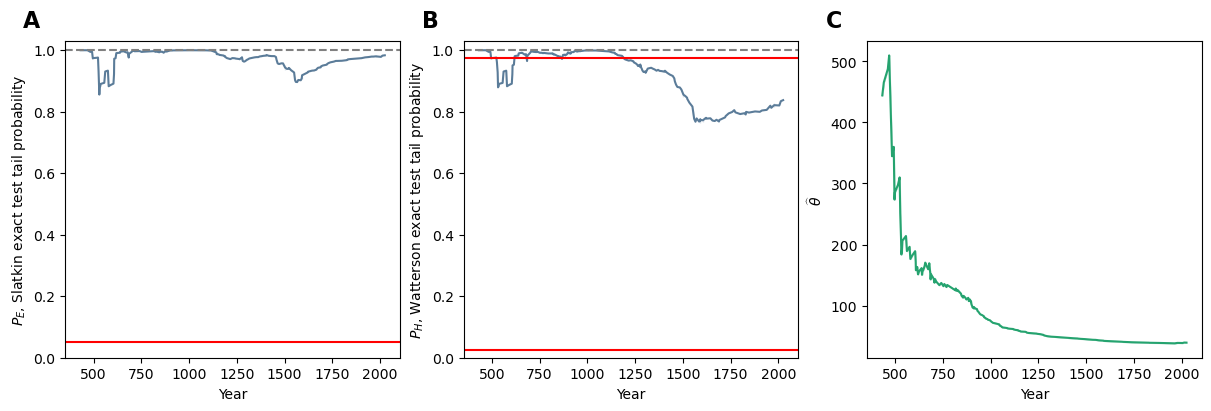

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True, sharex=True)
colors = sns.xkcd_palette(["slate blue", "teal green"])

ax = axs[0]
dplot = ps.query("kind == 'slatkin'")
sns.lineplot(dplot, x="year", y="p_tail", ax=ax, color=colors[0])

ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0.05, color="red")
# ax.axhline(0.975, color="red")
ax.set_ylim(0, 1.03)

ax = axs[1]
dplot = ps.query("kind == 'watterson'")
sns.lineplot(dplot, x="year", y="p_tail", ax=ax, color=colors[0])

ax.set_ylabel("$P_H$, Watterson exact test tail probability")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0.025, color="red")
ax.axhline(0.975, color="red")
ax.set_ylim(0, 1.03)


ax = axs[2]
sns.lineplot(ps, x="year", y="theta", ax=ax, color=colors[1])

ax.set_ylabel("$\\widehat \\theta$")

for i, ax in enumerate(axs.flatten()):
    ax.set_xlabel("Year")

    ax.text(
        -0.1,
        1.1,
        chr(65 + i),
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="center",
    )

fig.savefig("plots/figure_2.pdf", bbox_inches="tight")
fig.savefig("plots/figure_2.png", dpi=600, bbox_inches="tight")

### Figure 3

In [21]:
SAMPLES = 10e5


def run_test_conditional(
    n, k, configuration, initial_configuration, samples=1e8, kind="slatkin"
):
    seed = random.randint(0, 2**16)
    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} --initial-configuration '{initial_configuration}' {int(samples)} | ewens-sampler test {kind} '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


def fit_theta_conditional(n, k, n0, k0):
    if k == k0:
        # return 0 as no mutations => theta = 4Nmu = 0
        return 0
    else:

        def ll(theta):
            return -(k - k0) * np.log(theta) + np.sum(
                [np.log(theta + i) for i in range(n0, n)]
            )

        result = opt.minimize_scalar(ll, bounds=(0, 1e7), method="bounded")

        return result.x


def get_windows(size):
    x = np.arange(432, 2025 - size + 1)
    return zip(x, x + size)


def compute_window(s, e, d, d_end, kind):
    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]
    initial_configuration = " ".join([str(x) for x in d["name"].value_counts()])
    n0 = d.shape[0]
    k0 = len(d["name"].unique())

    d_end = popes.query("start < @e")
    end_configuration = " ".join([str(x) for x in d_end["name"].value_counts()])
    n = d_end.shape[0]
    k = len(d_end["name"].unique())

    p_tail = run_test_conditional(
        n, k, end_configuration, initial_configuration, SAMPLES, kind
    )

    theta = fit_theta_conditional(n, k, n0, k0)

    d_win = popes.query("start >= @s and start < @e")
    k_win = len(d_win["name"].unique())
    n_win = d_win.shape[0]

    win_counts = d_win["name"].value_counts()
    win_freqs = (win_counts / win_counts.sum()).values
    win_entropy = -(win_freqs * np.log(win_freqs)).sum()

    return {
        "year": year,
        "pope": pope,
        "n": n,
        "k": k,
        "window_start": s,
        "window_end": e,
        "window_size": size,
        "n0": n0,
        "k0": k0,
        "n_win": n_win,
        "k_win": k_win,
        "win_entropy": win_entropy,
        "theta": theta,
        "p_tail": p_tail,
        "kind": kind,
    }


# size of the temporal window
size = 200

if Path("./output/figure_3.csv").exists():
    print("using existing dataframe for figure 3")
    ps_windowed = pd.read_csv("./output/figure_3.csv")
else:
    print("computing data for figure 3")

    args = []

    for s, e in get_windows(size):
        d = popes.query("start <= @s")
        d_end = popes.query("start < @e")
        args.extend([(s, e, d, d_end, "slatkin"), (s, e, d, d_end, "watterson")])

    rows = list(
        tqdm(
            Parallel(n_jobs=-1, return_as="generator")(
                delayed(compute_window)(*x) for x in args
            ),
            total=len(args),
        )
    )

    ps_windowed = pd.DataFrame.from_records(rows)
    ps_windowed.to_csv("./output/figure_3.csv")

computing data for figure 3


  0%|          | 0/2788 [00:00<?, ?it/s]

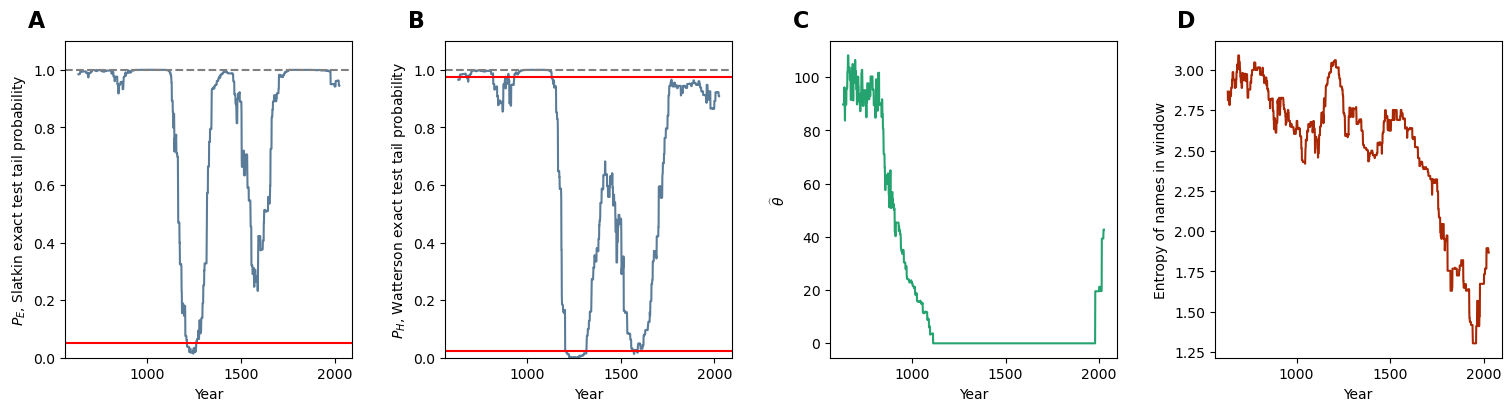

In [24]:
fig, axs = plt.subplots(
    1,
    4,
    figsize=(15, 4),
    constrained_layout=True,
    sharex=True,
    gridspec_kw={"wspace": 0.1},
)
colors = sns.xkcd_palette(["slate blue", "teal green", "rust red"])

ax = axs[0]
dplot = ps_windowed.query(f"window_size == @size and kind == 'slatkin'")

sns.lineplot(dplot, x="window_end", y="p_tail", ax=ax, color=colors[0])

ax.set_ylabel("$P_E$, Slatkin exact test tail probability")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0.05, color="red")
ax.set_ylim(0, 1.1)

ax = axs[1]
dplot = ps_windowed.query(f"window_size == @size and kind == 'watterson'")

sns.lineplot(dplot, x="window_end", y="p_tail", ax=ax, color=colors[0])

ax.set_ylabel("$P_H$, Watterson exact test tail probability")
ax.axhline(1, color="gray", linestyle="--")
ax.axhline(0.025, color="red")
ax.axhline(0.975, color="red")
ax.set_ylim(0, 1.1)

ax = axs[2]
sns.lineplot(dplot, x="window_end", y="theta", ax=ax, color=colors[1])
ax.set_ylabel("$\\widehat \\theta$")

ax = axs[3]
sns.lineplot(dplot, x="window_end", y="win_entropy", ax=ax, color=colors[2])
ax.set_ylabel("Entropy of names in window")

for i, ax in enumerate(axs.flatten()):
    ax.set_xlabel("Year")

    ax.text(
        -0.1,
        1.1,
        chr(65 + i),
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="center",
    )

fig.savefig(f"plots/figure_3.png", dpi=600, bbox_inches="tight")
fig.savefig(f"plots/figure_3.pdf", bbox_inches="tight")